# 02 · Think in three dimensions

[Run this notebook in your browser ↗](https://jltobias.github.io/JupyterLite-Global-Fishing-Watch-and-Dark-Vessels/lab/index.html?path=02_ocean_in_3d.ipynb)

**Evidence: observed study data on the globe; a separate synthetic ocean scene.** Use the globe to inspect spatial relationships without a map seam, then use a cutaway to reason about what a sensor can and cannot observe.

[Study data](https://doi.org/10.6084/m9.figshare.24309475), CC BY 4.0; coastline: Natural Earth, public domain. No external basemap or map-service token is required. WebGL is needed for the 3D views.

Run the setup cell first. Browser Python downloads numerical packages on first use. Core exercises use bundled files; live access is optional. Export your notebook to preserve work.

In [1]:
import sys
if sys.platform == "emscripten":
    import micropip
    await micropip.install(["numpy", "pandas", "matplotlib", "scipy", "plotly"])
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import oceanlab as lab
from IPython.display import display
print("Runtime:", sys.version.split()[0], "| NumPy:", np.__version__, "| pandas:", pd.__version__)

Runtime: 3.13.14 | NumPy: 2.3.3 | pandas: 2.3.2


## Rotate the observed ocean
Drag to rotate, scroll to zoom, and hover for cell values. Color is log10 of the summed normalized activity proxy in 1° bins. All points have a small illustrative altitude to avoid overlap with the sphere; altitude is **not** a data variable.

In [2]:
lab.show(lab.globe())

<iframe title="An ocean without map edges | drag to rotate" srcdoc="<html>
<head><meta charset="utf-8" /></head>
<body>
 <div> <script type="text/javascript">window.PlotlyConfig = {MathJaxConfig: 'local'};</script>
 <script charset="utf-8" src="https://cdn.plot.ly/plotly-3.3.0.min.js" integrity="sha256-bO3dS6yCpk9aK4gUpNELtCiDeSYvGYnK7jFI58NQnHI=" crossorigin="anonymous"></script> <div id="95280cf5-3297-4897-9e65-6f16e2fe4963" class="plotly-graph-div" style="height:650px; width:100%;"></div> <script type="text/javascript"> window.PLOTLYENV=window.PLOTLYENV || {}; if (document.getElementById("95280cf5-3297-4897-9e65-6f16e2fe4963")) { Plotly.newPlot( "95280cf5-3297-4897-9e65-6f16e2fe4963", [{"colorscale":[[0,"#0d384e"],[1,"#0d384e"]],"hoverinfo":"skip","opacity":0.96,"showscale":false,"surfacecolor":{"dtype":"f8","bdata":"...","shape":"60, 100"},"x":{"dtype":"f8","bdata":"B1wUMyamkbwVFBx\u002fDZ2RvJN3rcPMgZG8scGMGIBUkby9v9IvVhWRvHFGyiWQxJC8mCjSPYFikLxZvREZHd+PvA6yNB9d2I68zck2Z9GxjbxVGeGQqWyMvOmzoMk0Cou8AZQEc+CLibwUERmqNvOHvLUiJbHcQYa8GzlsPZF5hLzuS7SqKpyCvEPKahaVq4C8TnG4yKBTfby40BJe3DF5vJdrdEsf9nS8SB4BtcakcLzVSbwJjIRovG1cplKJTF+8cP62JW7fSrxihCSi0+sxPPr8I5UCYVY8Q5OoVf8XZDzuG4TVxupsPC5BDbLfz3I8u9nCqvcWdzxld0B8QkZ7PDgB2NZvWX88CFwUMyamgTyLJ8wSY42DPHKzOkl4YIU8hBa4W4Qdhzzi3p6GvMKIPOeFM5ZuToo8Xiw6pgK\u002fizy4PW3G\u002fBKNPOyNI4L+SI48sjmSSchfjzxy8ppdHSuQPDDjB+arlZA8kpHC5iHvkDxwo+knIzeRPIhFF3BlbZE84jjk0LCRkTwai4\u002fg36ORPBqLj+Dfo5E84jjk0LCRkTyIRRdwZW2RPHCj6ScjN5E8k5HC5iHvkDww4wfmq5WQPHPyml0dK5A8tDmSSchfjzzsjSOC\u002fkiOPLs9bcb8Eo08Xiw6pgK\u002fizznhTOWbk6KPOXenoa8wog8hBa4W4Qdhzx0szpJeGCFPI8nzBJjjYM8CFwUMyamgTw8AdjWb1l\u002fPG13QHxCRns8u9nCqvcWdzwxQQ2y389yPO4bhNXG6mw8TJOoVf8XZDwM\u002fSOVAmFWPPCEJKLT6zE8B\u002f62JW7fSrx+XKZSiUxfvNVJvAmMhGi8RB4BtcakcLyPa3RLH\u002fZ0vLDQEl7cMXm8V3G4yKBTfbxDymoWlauAvO5LtKoqnIK8GzlsPZF5hLyxIiWx3EGGvBERGao284e8AZQEc+CLibzps6DJNAqLvFUZ4ZCpbIy8y8k2Z9GxjbwMsjQfXdiOvFm9ERkd34+8mCjSPYFikLxxRsolkMSQvLy\u002f0i9WFZG8sMGMGIBUkbySd63DzIGRvBUUHH8NnZG8B1wUMyamkbxrAb3Y7z+rv5eHjV\u002fkMau\u002f2cxJbtAHq7\u002fLYuVk38Gqv2KIRlxZYKq\u002fZWT026Ljqb88SHZyPEypv0DNzjDCmqi\u002fRGebCevPp78LQn4UiOymv7\u002fPlLaD8aW\u002fvjbZsODfpL9rr2cVubijv5TFuiQ9faK\u002fPjcKFLIuob8EeR984ZyfvxqSFn\u002fIu5y\u002fSG\u002fqARG9mb8IbsBd0aOWv2lQPUU7c5O\u002fAa6eeZgukL849Q\u002fOjrKJv2coA1dv7YK\u002fSv34MJopeL94+W3m2r5kv2H8yIGEq0s\u002fAhWt2L1GcT9uXlcSPAZ\u002fPwXjfqLfUoY\u002fi8XhN54LjT8eA74ANtORP2B8Pwo9DpU\u002fD03ks48zmD9tAb3Y7z+bPxzCNgs5MJ4\u002fqA4q6bGAoD89YYZkRNihP\u002f4WTs5xHaM\u002fpatU8+pOpD9uXCvwdGulP50quXXqcaY\u002fU0OU9zxhpz+hIeXCdTioP2nvs\u002fy29qg\u002f2QCahjybqT+5rOvIXCWqP5QcimGJlKo\u002fc9+otk\u002foqj+I8+9sWSCrP7OAgMBsPKs\u002fs4CAwGw8qz+I8+9sWSCrP3PfqLZP6Ko\u002flByKYYmUqj+5rOvIXCWqP9kAmoY8m6k\u002fa++z\u002fLb2qD+iIeXCdTioP1NDlPc8Yac\u002foCq5depxpj9uXCvwdGulP6WrVPPqTqQ\u002fABdOznEdoz89YYZkRNihP6kOKumxgKA\u002fI8I2Czkwnj9tAb3Y7z+bPxJN5LOPM5g\u002fZnw\u002fCj0OlT8eA74ANtORP5DF4TeeC40\u002fBeN+ot9Shj98XlcSPAZ\u002fPxAVrdi9RnE\u002fO\u002f3IgYSrSz8o+W3m2r5kv1f9+DCaKXi\u002fZygDV2\u002ftgr8x9Q\u002fOjrKJv\u002futnnmYLpC\u002fYlA9RTtzk78PbsBd0aOWv0hv6gERvZm\u002fGpIWf8i7nL8EeR984Zyfvzw3ChSyLqG\u002fksW6JD19or9rr2cVubijv7422bDg36S\u002fv8+UtoPxpb8JQn4UiOymv0Jnmwnrz6e\u002fQM3OMMKaqL88SHZyPEypv2Vk9Nui46m\u002fYIhGXFlgqr\u002fKYuVk38Gqv9jMSW7QB6u\u002fl4eNX+Qxq79rAb3Y7z+rv6EeosQMNru\u002ftjv+YwYou7\u002fLhBy3Af66vwCzMw4quLq\u002fNk4BaMdWur+z3pInPtq5v1HJyqwOQ7m\u002fy4EL0NSRuL81fJFBR8e3vzN3Ic025La\u002fdD7Ngo3ptb81w6zFTdi0vwdBhEGRsbO\u002fvv5pyId2sr+D+JYZdiixv\u002f6SSiVpka+\u002fctAqmVuxrL9CQhBMurOpvzk1XXiam6a\u002fawAHqCxso7+ESuFquSigv3HIS+g7qZm\u002fwslsRZHmkr9bj6re1SCIv0RGi\u002fZTt3S\u002fzdcaZXqhWz8AqrokeUCBP9LmMWT6+o4\u002fI2ySG8ZKlj8sVotaFAGdP74DYFW+zKE\u002fVd\u002fhTJkGpT855IvExyqoP6MeosQMNqs\u002fLpNwA0Ulrj8flasQtXqwPyGxg+PK0bE\u002fqnheUYIWsz+rQ66gjEe0P3aMRGCvY7U\u002fiSx0q8Vptj\u002fWEP1XwVi3P5UrigysL7g\u002fYZCiPqjtuD+o9QcX8pG5PyMzlzvgG7o\u002f\u002f6PafeSKuj+4eJptjN66Px3k086BFrs\u002fXYmd8ooyuz9diZ3yijK7Px3k086BFrs\u002

## Check the geometry
The conversion from longitude and latitude to a unit sphere is explicit. At 0° longitude, 0° latitude, the point is (1,0,0). The Earth is approximated as a sphere for visualization. This does not calculate precise navigational distances.

In [3]:
example = pd.DataFrame({"lon": [0,90,0], "lat": [0,0,90]})
x,y,z = lab.sphere(example.lon.to_numpy(), example.lat.to_numpy())
display(example.assign(x=x, y=y, z=z).round(6))

,lon,lat,x,y,z
0,0,0,1.0,0.0,0.0
1,90,0,0.0,1.0,0.0
2,0,90,0.0,0.0,1.0


## From orbit to ecosystem
This **synthetic** scene separates the surface vessel observation from the ecosystem below. SAR does not see fish stocks or the seabed through seawater. The bathymetry, satellite height, beam positions and vessels are illustrative, with no geographic claim.

In [4]:
lab.show(lab.ocean_scene())

<iframe title="From orbit to ecosystem | conceptual 3D scene" srcdoc="<html>
<head><meta charset="utf-8" /></head>
<body>
 <div> <script type="text/javascript">window.PlotlyConfig = {MathJaxConfig: 'local'};</script>
 <script charset="utf-8" src="https://cdn.plot.ly/plotly-3.3.0.min.js" integrity="sha256-bO3dS6yCpk9aK4gUpNELtCiDeSYvGYnK7jFI58NQnHI=" crossorigin="anonymous"></script> <div id="6fcde083-8c34-427e-ba24-fd31b3b4c59a" class="plotly-graph-div" style="height:650px; width:100%;"></div> <script type="text/javascript"> window.PLOTLYENV=window.PLOTLYENV || {}; if (document.getElementById("6fcde083-8c34-427e-ba24-fd31b3b4c59a")) { Plotly.newPlot( "6fcde083-8c34-427e-ba24-fd31b3b4c59a", [{"colorscale":[[0.0,"rgb(209, 238, 234)"],[0.16666666666666666,"rgb(168, 219, 217)"],[0.3333333333333333,"rgb(133, 196, 201)"],[0.5,"rgb(104, 171, 184)"],[0.6666666666666666,"rgb(79, 144, 166)"],[0.8333333333333334,"rgb(59, 115, 143)"],[1.0,"rgb(42, 86, 116)"]],"hovertemplate":"Synthetic seafloor\u003cextra\u003e\u003c\u002fextra\u003e","name":"Seafloor","showscale":false,"x":{"dtype":"f8","bdata":"AAAAAAAAJMAmtJfQXkIjwExoL6G9hCLAchzHcRzHIcCY0F5CewkhwL6E9hLaSyDAx3Ecx3EcH8AT2ktoL6EdwF9CewntJRzAq6qqqqqqGsD3EtpLaC8ZwEN7Ce0ltBfAjuM4juM4FsDaS2gvob0UwCa0l9BeQhPAchzHcRzHEcC+hPYS2ksQwBTaS2gvoQ3ArKqqqqqqCsBEewntJbQHwNxLaC+hvQTAchzHcRzHAcAY2ktoL6H9v0h7Ce0ltPe\u002fcBzHcRzH8b9AewntJbTnv0B7Ce0ltNe\u002fAAAAAAAAAABAewntJbTXP0B7Ce0ltOc\u002fcBzHcRzH8T9AewntJbT3PxDaS2gvof0\u002fcBzHcRzHAUDYS2gvob0EQEB7Ce0ltAdAqKqqqqqqCkAQ2ktoL6ENQLyE9hLaSxBAcBzHcRzHEUAktJfQXkITQNpLaC+hvRRAjuM4juM4FkBCewntJbQXQPQS2ktoLxlAqKqqqqqqGkBcQnsJ7SUcQBDaS2gvoR1AyHEcx3EcH0C+hPYS2ksgQJjQXkJ7CSFAchzHcRzHIUBMaC+hvYQiQCa0l9BeQiNAAAAAAAAAJEAAAAAAAAAkwCa0l9BeQiPATGgvob2EIsByHMdxHMchwJjQXkJ7CSHAvoT2EtpLIMDHcRzHcRwfwBPaS2gvoR3AX0J7Ce0lHMCrqqqqqqoawPcS2ktoLxnAQ3sJ7SW0F8CO4ziO4zgWwNpLaC+hvRTAJrSX0F5CE8ByHMdxHMcRwL6E9hLaSxDAFNpLaC+hDcCsqqqqqqoKwER7Ce0ltAfA3EtoL6G9BMByHMdxHMcBwBjaS2gvof2\u002fSHsJ7SW0979wHMdxHMfxv0B7Ce0ltOe\u002fQHsJ7SW0178AAAAAAAAAAEB7Ce0ltNc\u002fQHsJ7SW05z9wHMdxHMfxP0B7Ce0ltPc\u002fENpLaC+h\u002fT9wHMdxHMcBQNhLaC+hvQRAQHsJ7SW0B0CoqqqqqqoKQBDaS2gvoQ1AvIT2EtpLEEBwHMdxHMcRQCS0l9BeQhNA2ktoL6G9FECO4ziO4zgWQEJ7Ce0ltBdA9BLaS2gvGUCoqqqqqqoaQFxCewntJRxAENpLaC+hHUDIcRzHcRwfQL6E9hLaSyBAmNBeQnsJIUByHMdxHMchQExoL6G9hCJAJrSX0F5CI0AAAAAAAAAkQAAAAAAAACTAJrSX0F5CI8BMaC+hvYQiwHIcx3EcxyHAmNBeQnsJIcC+hPYS2ksgwMdxHMdxHB\u002fAE9pLaC+hHcBfQnsJ7SUcwKuqqqqqqhrA9xLaS2gvGcBDewntJbQXwI7jOI7jOBbA2ktoL6G9FMAmtJfQXkITwHIcx3EcxxHAvoT2EtpLEMAU2ktoL6ENwKyqqqqqqgrARHsJ7SW0B8DcS2gvob0EwHIcx3EcxwHAGNpLaC+h\u002fb9IewntJbT3v3Acx3Ecx\u002fG\u002fQHsJ7SW0579AewntJbTXvwAAAAAAAAAAQHsJ7SW01z9AewntJbTnP3Acx3Ecx\u002fE\u002fQHsJ7SW09z8Q2ktoL6H9P3Acx3EcxwFA2EtoL6G9BEBAewntJbQHQKiqqqqqqgpAENpLaC+hDUC8hPYS2ksQQHAcx3EcxxFAJLSX0F5CE0DaS2gvob0UQI7jOI7jOBZAQnsJ7SW0F0D0EtpLaC8ZQKiqqqqqqhpAXEJ7Ce0lHEAQ2ktoL6EdQMhxHMdxHB9AvoT2EtpLIECY0F5CewkhQHIcx3EcxyFATGgvob2EIkAmtJfQXkIjQAAAAAAAACRAAAAAAAAAJMAmtJfQXkIjwExoL6G9hCLAchzHcRzHIcCY0F5CewkhwL6E9hLaSyDAx3Ecx3EcH8AT2ktoL6EdwF9CewntJRzAq6qqqqqqGsD3EtpLaC8ZwEN7Ce0ltBfAjuM4juM4FsDaS2gvob0UwCa0l9BeQhPAchzHcRzHEcC+hPYS2ksQwBTaS2gvoQ3ArKqqqqqqCsBEewntJbQHwNxLaC+hvQTAchzHcRzHAcAY2ktoL6H9v0h7Ce0ltPe\u002fcBzHcRzH8b9AewntJbTnv0B7Ce0ltNe\u002fAAAAAAAAAABAewntJbTXP0B7Ce0ltOc\u002fcBzHcRzH8T9AewntJbT3PxDaS2gvof0\u002fcBzHcRzHAUDYS2gvob0EQEB7Ce0ltAdAqKqqqqqqCkAQ2ktoL6ENQLyE9hLaSxBAcBzHcRzHEUAktJfQXkITQNpLaC+hvRRAjuM4juM4FkBCewntJbQXQPQS2ktoLxlAqKqqqqqqGkBcQnsJ7SUcQBDaS2gvoR1AyHEcx3EcH0C+hPYS2ksgQJjQXkJ7CSFAchzHcRzHIUBMaC+hvYQiQCa0l9BeQiNAAAAAAAAAJEAAAAAAAAAkwCa0l9BeQiPATGgvob2EIsByHMdxHMchwJjQXkJ7CSHAvoT2EtpLIMDHcRzHcRwfwBPaS2gvoR3AX0J7Ce0lHMCrqqqqqqoawPcS2ktoLxnAQ3sJ7SW0F8CO4ziO4zgWwNpLaC+hvRTAJrSX0F5CE8ByHMdxHMcRwL6E9hLaSxDAFNpLaC+hDcCsqqqqqqoKwER7Ce0ltAfA3EtoL6G9BMByHMdxHMcBwBjaS2gvof2\u002fSHsJ7SW0979wHMdxHMfxv0B7Ce0ltOe\u002fQHsJ7SW0178AAAAAAAAAAEB7Ce0ltNc\u002fQHsJ7SW05z9wHMdxHMfxP0B7Ce0ltPc\u002fENpLaC+h\u002fT9wHMdxHMcBQNhLaC+hvQRAQHsJ7SW0B0CoqqqqqqoKQBDaS2gvoQ1AvIT2EtpLEEBwHMdxHMcRQCS0l9

## A 2D companion
A globe hides the far side and can make precise value comparisons difficult. Keep a flat map and a data table beside it. The 3D view is a reasoning aid, not an automatic improvement in analytical accuracy.

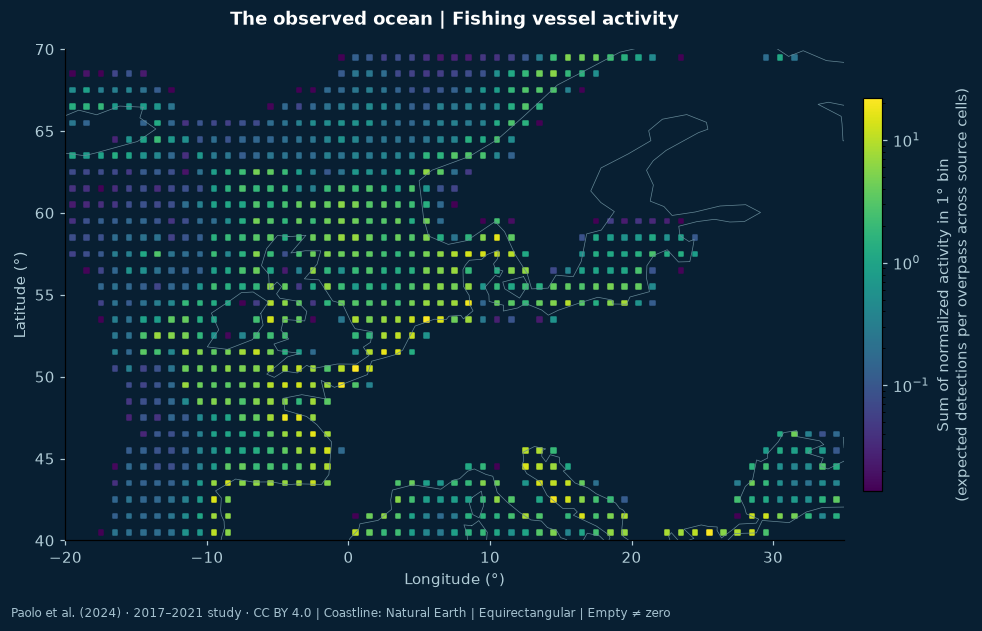

In [5]:
lab.map2d(bbox=(-20,40,35,70)); plt.show()

**Try it:** choose a pattern that is clearer on the globe and one that is clearer in 2D. Identify every vertical dimension in the scene that could be mistaken for a measured quantity. Write captions that prevent that mistake.